In [1]:
import os
import lmetk
print(os.environ['PROJECT_ROOT'])  # should print the detected root

import hydra
from lmetk.data.utils import reconstruct_datetime_from_features
import numpy as np
from lmetk.data.datasets import SWDataset, SWBatchDataset

%load_ext autoreload
%autoreload 2

/home/levtel/projects/TabPHM


### Refactored version

In [2]:
data_name = "ETTh1"

with hydra.initialize(version_base="1.3", config_path="../configs", job_name="run"):
    # print('Current config file: ', config_file)
    parameters = hydra.compose(
        config_name="run.yaml",
        overrides=[f"datasource={data_name}"],
        return_hydra_config=True,
    )
    dataset_loader2 = hydra.utils.instantiate(parameters.datasource)
    dataset_loader2._pipeline()


# Get params of splitting and sliding
data_splitter_params = parameters.datasource.data_splitter
seq_len = data_splitter_params.seq_len
label_len = data_splitter_params.label_len
pred_len = data_splitter_params.pred_len

# get data
splitted_data, splitted_timestamps = dataset_loader2.get_data()

dataset_train = SWDataset(
    features=splitted_data["train"],
    time_features=splitted_timestamps["train"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)

dataset_val = SWDataset(
    features=splitted_data["val"],
    time_features=splitted_timestamps["val"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)
dataset_test = SWDataset(
    features=splitted_data["test"],
    time_features=splitted_timestamps["test"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)
print(f"Train dataset size: {dataset_train.__len__()}")
print(f"Validation dataset size: {dataset_val.__len__()}")
print(f"Test dataset size: {dataset_test.__len__()}")

Train dataset size: 8449
Validation dataset size: 2785
Test dataset size: 5805


In [7]:
for i in range(2783, 2787):
    seq_x, seq_y, seq_x_mark, seq_y_mark = dataset_val.__getitem__(i)
    print("Index", i)
    print(
        f"seq_x shape: {seq_x.shape}, seq_y shape: {seq_y.shape}, seq_x_mark shape: {seq_x_mark.shape}, seq_y_mark shape: {seq_y_mark.shape}"
    )

Index 2783
seq_x shape: torch.Size([96, 1]), seq_y shape: torch.Size([144, 1]), seq_x_mark shape: torch.Size([96, 4]), seq_y_mark shape: torch.Size([144, 4])
Index 2784
seq_x shape: torch.Size([96, 1]), seq_y shape: torch.Size([144, 1]), seq_x_mark shape: torch.Size([96, 4]), seq_y_mark shape: torch.Size([144, 4])


AssertionError: Target sequence indices out of bounds

In [8]:
for mode in ["val"]:
    batch_dataset = SWBatchDataset(
        features=splitted_data[mode],
        time_features=splitted_timestamps[mode],
        seq_len=seq_len,
        label_len=label_len,
        pred_len=pred_len,
        stride=1,
    )
    print(f" {mode} size: {batch_dataset.__len__()}")
    for i in range(batch_dataset.__len__()):
        batch_dataset.__getitem__(i)
    seq_x2, seq_y2, seq_x_mark2, seq_y_mark2 = batch_dataset.__getitem__(i)


seq_x2, seq_y2, seq_x_mark2, seq_y_mark2 = batch_dataset.__getitem__(4)
seq_x1, seq_y1, seq_x_mark1, seq_y_mark1 = dataset_val.__getitem__(4)


np.testing.assert_array_almost_equal(seq_x2, seq_x1)

 val size: 2785


### Railway: classical dataset 

In [ ]:
import hydra

data_name = "railway"

with hydra.initialize(version_base="1.3", config_path="../configs", job_name="run"):
    # print('Current config file: ', config_file)
    parameters = hydra.compose(
        config_name="run.yaml",
        overrides=[f"datasource={data_name}"],
        return_hydra_config=True,
    )
    dataset_loader2 = hydra.utils.instantiate(parameters.datasource)
    dataset_loader2._pipeline()

In [ ]:
data_splitter_params = parameters.datasource.data_splitter
seq_len = data_splitter_params.seq_len
label_len = data_splitter_params.label_len
pred_len = data_splitter_params.pred_len

# get data
splitted_data, splitted_timestamps = dataset_loader2.get_data()

dataset_train = SWDataset(
    features=splitted_data["train"],
    time_features=splitted_timestamps["train"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)

dataset_val = SWDataset(
    features=splitted_data["val"],
    time_features=splitted_timestamps["val"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)
dataset_test = SWDataset(
    features=splitted_data["test"],
    time_features=splitted_timestamps["test"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
)
print(f"Train dataset size: {dataset_train.__len__()}")
print(f"Validation dataset size: {dataset_val.__len__()}")
print(f"Test dataset size: {dataset_test.__len__()}")

TypeError: SWDataset.__init__() missing 1 required positional argument: 'features'

In [11]:
# Test should stard from "2023-01-24 00:00:00" (if apply_lookback == False then __getitem__(seq_len) otherwise __getitem__(0))
seq_x, seq_y, seq_x_mark, seq_y_mark = dataset_test.__getitem__(seq_len)
reconstruct_datetime_from_features(
    seq_x_mark.numpy(), ["year", "month", "day", "weekday", "hour"]
)[:3]

0   2023-01-24 00:00:00
1   2023-01-24 01:00:00
2   2023-01-24 02:00:00
dtype: datetime64[ns]

In [12]:
str(
    reconstruct_datetime_from_features(
        seq_x_mark.numpy(), ["year", "month", "day", "weekday", "hour"]
    )[0]
) == "2023-01-24 00:00:00"

True

In [13]:
seq_x, seq_y, seq_x_mark, seq_y_mark = dataset_val.__getitem__(seq_len)
reconstruct_datetime_from_features(
    seq_x_mark.numpy(), ["year", "month", "day", "weekday", "hour"]
)[:3]

0   2022-08-02 00:00:00
1   2022-08-02 01:00:00
2   2022-08-02 02:00:00
dtype: datetime64[ns]

### Check of tsfresh

In [2]:
import pandas as pd

df = dataset_loader2.df
df_stamp = dataset_loader2.df_stamp

df = df.rename(columns={'Bahnlast':'y'})

df_stamp = df_stamp.to_frame()
df_stamp = df_stamp.rename(columns={'datetime':'time'})

new_df = pd.concat([df_stamp, df], axis=1)

new_df['id'] = pd.Series(['A'] * new_df.shape[0])

NameError: name 'dataset_loader2' is not defined

In [140]:
from tsfresh.utilities.dataframe_functions import roll_time_series
short_df = new_df[['id','time', 'y', 'Pully']].iloc[:49]
df_rolled = roll_time_series(short_df, column_id="id", column_sort="time", rolling_direction=24, max_timeshift=24, min_timeshift=24)

df_rolled



Rolling: 100%|██████████| 3/3 [00:00<00:00, 444.55it/s]


,id,time,y,Pully
25,"(A, 2018-04-03 00:00:00)",2018-04-02 00:00:00,130.204375,6.300
26,"(A, 2018-04-03 00:00:00)",2018-04-02 01:00:00,87.320175,6.350
27,"(A, 2018-04-03 00:00:00)",2018-04-02 02:00:00,79.965675,5.525
28,"(A, 2018-04-03 00:00:00)",2018-04-02 03:00:00,84.284475,4.900
29,"(A, 2018-04-03 00:00:00)",2018-04-02 04:00:00,108.719675,5.450
30,"(A, 2018-04-03 00:00:00)",2018-04-02 05:00:00,174.614275,5.350
31,"(A, 2018-04-03 00:00:00)",2018-04-02 06:00:00,254.527350,5.575
32,"(A, 2018-04-03 00:00:00)",2018-04-02 07:00:00,264.813075,5.600
33,"(A, 2018-04-03 00:00:00)",2018-04-02 08:00:00,271.176775,5.075
34,"(A, 2018-04-03 00:00:00)",2018-04-02 09:00:00,252.122900,5.650


In [46]:
from tsfresh import extract_features
from tsfresh.utilities.dataframe_functions import roll_time_series
df = pd.DataFrame({
   "id": [1, 1, 1, 1, 1, 1],
   "time": [1, 2, 3, 4, 8, 9],
   "x": [1, 2, 3, 4, 10, 11],
   "y": [5, 6, 7, 8, 12, 13],
})
from tsfresh.utilities.dataframe_functions import roll_time_series
df_rolled = roll_time_series(df, column_id="id", column_sort="time",  rolling_direction=2, max_timeshift=4, min_timeshift=2)


/home/levtel/miniconda3/envs/phm2/lib/python3.11/site-packages/tsfresh/utilities/dataframe_functions.py:520: UserWarning: Your time stamps are not uniformly sampled, which makes rolling nonsensical in some domains.
  warnings.warn(


Rolling: 100%|██████████| 3/3 [00:00<00:00, 334.52it/s]


In [41]:
df

,id,time,x,y
0,1,1,1,5
1,1,2,2,6
2,1,3,3,7
3,1,4,4,8
4,1,8,10,12
5,1,9,11,13


In [42]:
df_rolled

,id,time,x,y
5,"(1, 4)",1,1,5
6,"(1, 4)",2,2,6
7,"(1, 4)",3,3,7
8,"(1, 4)",4,4,8
0,"(1, 9)",2,2,6
1,"(1, 9)",3,3,7
2,"(1, 9)",4,4,8
3,"(1, 9)",8,10,12
4,"(1, 9)",9,11,13


In [47]:
extracted_features = extract_features(df[["x", "time",'id']], column_id='id', column_sort="time")

Feature Extraction: 100%|██████████| 1/1 [00:00<00:00, 14.22it/s]


In [4]:

df_rolled = roll_time_series(df, column_id="id", column_sort="time", rolling_direction=1, max_timeshift=1, min_timeshift=0)
df_rolled

NameError: name 'roll_time_series' is not defined

In [163]:
from tsfresh import extract_features
df_features = extract_features(df_rolled, column_id="id", column_sort="time")
df_features['x__sum_values']

Feature Extraction: 100%|██████████| 12/12 [00:00<00:00, 236.55it/s]


1  1     1.0
   2     3.0
   3     5.0
   4     7.0
2  8    10.0
   9    21.0
Name: x__sum_values, dtype: float64

In [159]:
from tsfresh.utilities.dataframe_functions import make_forecasting_frame
x,y = make_forecasting_frame(df['x'], max_timeshift=1, rolling_direction=1, kind='kind')

Rolling: 100%|██████████| 6/6 [00:00<00:00, 826.14it/s]


### Railway efficient dataset

In [17]:
import hydra
from lmetk.data.preprocessing.preprocessor import PreProcessor
from lmetk.data.datasets.context_dataset import (
    ContextBatchDataset,
)

data_name = "railway_dummy_leak"

with hydra.initialize(version_base="1.3", config_path="../configs", job_name="run"):
    # print('Current config file: ', config_file)
    parameters = hydra.compose(
        config_name="run.yaml",
        overrides=[f"datasource={data_name}"],
        return_hydra_config=True,
    )
    dataset_loader2 = hydra.utils.instantiate(parameters.datasource)
    

preprocessor = PreProcessor(dataset_loader2)
preprocessor.pipeline()

data_lst, source_transforms_lst, multisource_transforms = preprocessor.get_processed_data()



data_dict = data_lst[0]
features = data_dict['features']
time_features = data_dict['timestamps']

transform_names = preprocessor.get_transform_names()
    
target_scaler_idx = transform_names.index('scaler_target')
scaler = source_transforms_lst[0][target_scaler_idx].transform_instance.scaler


data_splitter_params = parameters.datasource.data_splitter
seq_len = data_splitter_params.seq_len
label_len = data_splitter_params.label_len
pred_len = data_splitter_params.pred_len


dataset_train = ContextBatchDataset(
    context=features["train"],
    target= data_dict['target']["train"],
    time_features=time_features["train"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
    stride=24
)

dataset_val = ContextBatchDataset(
    context=features["val"], 
    target= data_dict['target']["val"],
    time_features=time_features["val"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
    stride=24
)
dataset_test = ContextBatchDataset(
    context=features["test"], 
    target= data_dict['target']["test"],
    time_features=time_features["test"],
    seq_len=seq_len,
    label_len=label_len,
    pred_len=pred_len,
    stride=24
)
print(f"Train dataset size: {dataset_train.__len__()}")
print(f"Validation dataset size: {dataset_val.__len__()}")
print(f"Test dataset size: {dataset_test.__len__()}")


# Test should stard from "2023-01-24 00:00:00"
d = dataset_test.__getitem__(7) # seq_len
print(
    reconstruct_datetime_from_features(
        d["target"]["x_mark"].long().numpy(),
        ["year", "month", "day", "weekday", "hour"],
    )[:2]
)

Train dataset size: 1576
Validation dataset size: 176
Test dataset size: 342
0   2023-01-24 00:00:00
1   2023-01-24 01:00:00
dtype: datetime64[ns]


In [18]:
seq_len

168

In [19]:
d = dataset_test.__getitem__(0)

In [20]:
print('x_shape: ', d['context']['x'].shape)
print('y_shape: ', d['context']['y'].shape)
print(reconstruct_datetime_from_features(d['context']['x_mark'].long().numpy(), ["year", "month", "day", "weekday", "hour"])[-5:])
print(reconstruct_datetime_from_features(d['context']['y_mark'].long().numpy(), ["year", "month", "day", "weekday", "hour"])[:5])

x_shape:  torch.Size([168, 53])
y_shape:  torch.Size([24, 53])
163   2023-01-23 19:00:00
164   2023-01-23 20:00:00
165   2023-01-23 21:00:00
166   2023-01-23 22:00:00
167   2023-01-23 23:00:00
dtype: datetime64[ns]
0   2023-01-24 00:00:00
1   2023-01-24 01:00:00
2   2023-01-24 02:00:00
3   2023-01-24 03:00:00
4   2023-01-24 04:00:00
dtype: datetime64[ns]


In [21]:
print('x_shape: ', d['target']['x'].shape)
print('y_shape: ', d['target']['y'].shape)
print(reconstruct_datetime_from_features(d['target']['x_mark'].long().numpy(), ["year", "month", "day", "weekday", "hour"])[-5:])
print(reconstruct_datetime_from_features(d['target']['y_mark'].long().numpy(), ["year", "month", "day", "weekday", "hour"])[:5])

x_shape:  torch.Size([168, 1])
y_shape:  torch.Size([24, 1])
163   2023-01-23 19:00:00
164   2023-01-23 20:00:00
165   2023-01-23 21:00:00
166   2023-01-23 22:00:00
167   2023-01-23 23:00:00
dtype: datetime64[ns]
0   2023-01-24 00:00:00
1   2023-01-24 01:00:00
2   2023-01-24 02:00:00
3   2023-01-24 03:00:00
4   2023-01-24 04:00:00
dtype: datetime64[ns]


In [27]:
d = dataset_test.__getitem__(1)

d['context']['y'][:, -1]

tensor([0.4384, 0.3008, 0.3035, 0.2995, 0.4033, 0.6239, 0.8387, 0.9211, 0.8671,
        0.7881, 0.7180, 0.6985, 0.7051, 0.7009, 0.7212, 0.7820, 0.8873, 0.9332,
        0.9052, 0.8148, 0.7486, 0.6834, 0.6159, 0.5769])

In [28]:
d['context']['x'][:, -1]

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

In [23]:

d['target']['y'][:, -1]

tensor([0.4151, 0.2810, 0.2395, 0.2597, 0.3733, 0.6013, 0.8281, 0.9067, 0.8666,
        0.7357, 0.6766, 0.6283, 0.6115, 0.5820, 0.6128, 0.6957, 0.7892, 0.8383,
        0.8015, 0.7499, 0.6600, 0.6282, 0.5466, 0.5160])

In [15]:
d['context']['x'].shape

torch.Size([168, 53])

In [12]:
from lmetk.data.datamodules import ContextBaseDataModule


train_dataset = ContextBatchDataset(
        features=splitted_data['train'],
        time_features=splitted_timestamps['train'],
        seq_len=seq_len,
        label_len=label_len,
        pred_len=pred_len,
        mask=dataset_loader2.data_dict["mask"],
        stride=24,
    )


val_dataset = ContextBatchDataset(
        features=splitted_data['val'],
        time_features=splitted_timestamps['val'],
        seq_len=seq_len,
        label_len=label_len,
        pred_len=pred_len,
        mask=dataset_loader2.data_dict["mask"],
        stride=24,
    )


test_dataset = ContextBatchDataset(
        features=splitted_data['test'],
        time_features=splitted_timestamps['test'],
        seq_len=seq_len,
        label_len=label_len,
        pred_len=pred_len,
        mask=dataset_loader2.data_dict["mask"],
        stride=24,
    )

datamodule = ContextBaseDataModule(
    dataset_train=train_dataset, 
    dataset_val=val_dataset, 
    dataset_test=test_dataset,

    train_batch_size=1,
    val_batch_size=1,
    test_batch_size=1,

    shuffle_train=False,
    shuffle_val=False,
    shuffle_test=False,
    )

In [13]:
train_dataset.__len__()

1583

In [139]:
# ["year", "month", "day", "weekday", "hour"]


In [140]:
batch = next(iter(datamodule.train_dataloader()))

In [141]:
batch['target']['x_mark'].int().shape

torch.Size([1, 24, 5])

In [142]:
batch['target']['y_mark'].int().shape

torch.Size([1, 24, 5])

In [143]:
batch['target']['x_mark'].int()[:,:3]

tensor([[[2018,    4,    2,    0,    0],
         [2018,    4,    2,    0,    1],
         [2018,    4,    2,    0,    2]]], dtype=torch.int32)

In [144]:
batch['target']['y_mark'].int()[:,:3]

tensor([[[2018,    4,    2,    0,    0],
         [2018,    4,    2,    0,    1],
         [2018,    4,    2,    0,    2]]], dtype=torch.int32)

In [145]:
datamodule.train_dataloader().__len__()

37969

In [ ]:
import torch
def damodule2sklearn_naive(dl):
    X, y = [], []
    for batch in iter(dl):
        x_target, y_target, x_t_time, y_t_time = batch['target']['x'], batch['target']['y'], batch['target']['x_mark'], batch['target']['y_mark']
        x_context, y_context, x_c_time, y_c_time = batch['context']['x'], batch['context']['y'], batch['context']['x_mark'], batch['context']['y_mark']
        
        y_context, y_c_time, x_target, x_t_time

        X.append(torch.concat([x_context[:, lag, :], x_target[:, lag, :]], dim=1))
        y.append(y_t[:, lag, :])

    return torch.concat(X).numpy(), torch.concat(y).numpy()

In [39]:
dl_to_sklearn__with_context_for_tabpfn(datamodule.train_dataloader(), lag=0)

NameError: name 'y_t' is not defined

In [ ]:
x_target, y_target, x_t_time, y_t_time = batch['target']['x'], batch['target']['y'], batch['target']['x_mark'], batch['target']['y_mark']
x_context, y_context, x_c_time, y_c_time = batch['context']['x'], batch['context']['y'], batch['context']['x_mark'], batch['context']['y_mark']

concat = torch.concat([x_context, x_t_time, x_target], dim=-1)

In [87]:
concat.shape

torch.Size([1, 48, 58])

In [ ]:
from lmetk.case_studies.railway_traction import SpatialDataModule

dm = SpatialDataModule(ts_in=24, batch_size=1)
dm.setup()


In [ ]:
dm.datasets['train']

TypeError: iteration over a 0-d tensor

In [82]:
def dl_to_sklearn__with_context_for_tabpfn_original(dl, lag=0):
    X, y = [], []
    for batch in iter(dl):
        x_c, y_c, x_t, y_t = batch
        X.append(torch.concat([x_t[:, lag, :], y_c.squeeze(2)], dim=1))
        y.append(y_t[:, lag, :])

    return torch.concat(X).numpy(), torch.concat(y).numpy()

X, y = dl_to_sklearn__with_context_for_tabpfn_original(dm.train_dataloader())

In [68]:
X.shape

(39193, 80)

In [25]:
import numpy as np

def generate_multivariate_sequence(B=5, V=10, total_values=1000, value_probs=None, seed=None):
    N = total_values // B
    if seed is not None:
        np.random.seed(seed)

    # Step 1: Define value probabilities (must sum to 1)
    if value_probs is None:
        # Example: skewed distribution (can be customized)
        value_probs = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])
    else:
        value_probs = np.array(value_probs)
        assert len(value_probs) == V, "value_probs must be of length V"
        assert np.isclose(np.sum(value_probs), 1.0), "value_probs must sum to 1"

    # Step 2: Sample 1000 values from the distribution to form the global bucket A
    bucket = np.random.choice(np.arange(V), size=total_values, p=value_probs, replace=True)
    np.random.shuffle(bucket)

    # Step 3: Fill output array round-by-round
    sequence = np.zeros((B, N), dtype=int)

    for round_idx in range(N):
        round_vals = bucket[round_idx * B : (round_idx + 1) * B]
        np.random.shuffle(round_vals)  # Shuffle for fairness/random assignment
        sequence[:, round_idx] = round_vals

    return sequence

# Example usage
seq = generate_multivariate_sequence()
print(seq.shape)  # (5, 200)
print(seq)


(5, 200)
[[6 6 1 8 5 1 5 1 7 2 5 4 8 4 6 0 6 6 9 9 2 4 8 3 0 6 4 7 4 8 6 8 4 4 6 5
  7 4 4 6 1 3 7 9 0 5 2 4 1 2 9 5 1 4 3 6 1 2 2 0 3 5 6 0 0 8 3 5 6 5 4 5
  8 3 8 8 3 4 3 7 2 5 7 1 9 5 7 9 2 6 3 8 8 0 3 0 0 3 6 2 8 3 0 8 3 4 9 8
  3 6 2 8 3 7 1 3 1 8 4 5 5 9 0 2 8 5 7 5 3 6 6 8 8 0 6 6 5 6 1 9 4 5 9 5
  5 3 7 7 0 1 2 9 3 4 0 4 8 7 1 9 9 6 7 2 2 7 4 6 4 9 5 6 8 0 1 0 1 5 7 9
  7 5 0 5 2 8 4 5 7 2 8 8 9 1 5 7 2 2 0 6]
 [9 0 8 0 0 8 0 9 0 4 1 7 5 0 2 9 7 5 9 3 7 6 3 1 6 2 5 5 7 6 9 2 8 5 7 0
  9 2 6 7 1 4 4 3 7 4 4 9 9 7 8 0 1 3 3 5 9 1 4 2 1 8 2 1 5 3 9 7 4 7 2 7
  5 5 1 3 6 2 8 2 5 0 4 9 6 8 0 8 3 0 9 1 7 0 7 5 0 7 6 3 5 7 2 9 3 3 1 8
  9 2 7 9 1 6 3 6 5 5 3 9 2 3 8 5 9 4 1 9 6 4 1 6 5 4 8 0 5 5 8 0 3 2 0 8
  8 9 1 4 6 8 7 8 5 6 7 1 2 0 3 9 6 0 1 9 7 0 7 8 3 7 6 1 6 2 8 1 2 3 3 5
  5 1 5 3 7 4 7 8 9 0 4 5 9 5 0 3 1 6 0 5]
 [6 3 0 6 1 6 9 4 4 9 8 2 5 8 9 5 6 9 0 0 1 5 3 3 3 1 0 2 1 2 1 0 8 5 8 1
  7 3 1 9 7 5 3 8 5 3 3 1 8 1 9 9 6 3 4 4 0 8 4 9 8 6 3 9 6 6 4 3 6 6 3 1
  3 2 4 2 9 5 5 1

In [28]:
np.unique(seq.flatten(), return_counts=True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 array([ 92,  98,  80, 110, 102, 119, 101,  95, 109,  94]))

In [30]:
from collections import Counter
import numpy as np

def predict_next_round(observed_values, initial_probs, total_values=1000, B=5):
    V = len(initial_probs)

    # Step 1: Expected total per value
    expected_counts = np.array(initial_probs) * total_values

    # Step 2: Count observed values
    observed_counts = Counter(observed_values)
    remaining_counts = np.array([
        expected_counts[v] - observed_counts.get(v, 0)
        for v in range(V)
    ])

    # If any count went negative due to noise, clip to 0
    remaining_counts = np.clip(remaining_counts, 0, None)

    # Step 3: Predict the most likely next 5 values (optional: sample instead)
    predicted_values = np.random.choice(
        np.arange(V),
        size=B,
        replace=False,
        p=remaining_counts / remaining_counts.sum()
    )

    return predicted_values


predict_next_round(seq.flatten(), [0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])

array([9, 2, 7, 0, 1])

In [ ]:
import numpy as np
import random
from collections import Counter

def generate_multiplayer_sequence(
    num_players=5,
    total_bucket_size=1000,
    value_domain=list(range(10)),
    latent_distributions=None,
    initial_bucket_distribution=None,
    seed=None
):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    V = len(value_domain)

    # Default latent distributions if not provided
    if latent_distributions is None:
        latent_distributions = {
            "A": np.array([0.2, 0.2, 0.2, 0.2, 0.01, 0.05, 0.05, 0.05, 0.025, 0.025][:V]),
            "B": np.array([0.2, 0.2, 0.2, 0.2, 0.01, 0.05, 0.05, 0.05, 0.025, 0.025][:V]),
            "C": np.array([0.01, 0.01, 0.01, 0.01, 0.1, 0.1, 0.2, 0.2, 0.15, 0.1][:V]),
        }

    for key in latent_distributions:
        latent_distributions[key] = latent_distributions[key][:V]
        latent_distributions[key] /= latent_distributions[key].sum()

    latent_keys = list(latent_distributions.keys())

    # Default initial bucket distribution: uniform
    if initial_bucket_distribution is None:
        initial_bucket_distribution = np.ones(V) / V

    bucket_counts = (initial_bucket_distribution * total_bucket_size).astype(int)
    bucket = []
    for val, count in zip(value_domain, bucket_counts):
        bucket.extend([val] * count)
    random.shuffle(bucket)

    # Number of rounds
    rounds = (len(bucket) // num_players) - 50
    sequence = np.zeros((num_players, rounds), dtype=int)
    latent_sequence = []

    for t in range(rounds):
        z_t = random.choice(latent_keys)
        latent_sequence.append(z_t)

        current_counts = Counter(bucket)
        remaining_values = list(current_counts.keys())
        remaining_counts = np.array([current_counts[v] for v in remaining_values])

        latent_probs = latent_distributions[z_t][remaining_values]
        latent_probs = latent_probs * remaining_counts
        if latent_probs.sum() == 0:
            latent_probs = np.ones_like(latent_probs)
        latent_probs /= latent_probs.sum()

        # Sample without replacement
        selected_values = np.random.choice(remaining_values, size=num_players, replace=False, p=latent_probs)

        for v in selected_values:
            bucket.remove(v)

        random.shuffle(selected_values)
        selected_values[-1] = sum(selected_values[:-1])
        sequence[:, t] = selected_values

    return sequence, latent_sequence

sequence, latent_sequence = generate_multiplayer_sequence(num_players=5, total_bucket_size=10000, value_domain=list(range(10)), latent_distributions=None, initial_bucket_distribution=None, seed=None)

ValueError: Fewer non-zero entries in p than size

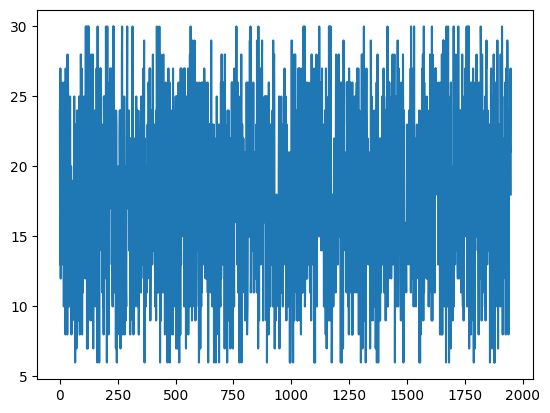

In [100]:
import matplotlib.pyplot as plt


# differentite sequence
sequence[-1, :-1,] - sequence[-1, 1:,]
plt.plot(sequence[-1])

In [ ]:
sequence[-1]

(115,)

In [72]:
latent_sequence[-5:]

['A', 'C', 'C', 'C', 'B']